# **Multi-Agent Planner**
![Multi-Agent Travel Planning](<Multi-Agent Travel Planning img.png>)

## PostgreSQL test 

In [ ]:
import os 
import certifi
from dotenv import load_dotenv

load_dotenv()

OPENAI_API_KEY = os.getenv("OPENAI_API_KEY")
BASE_URL = os.getenv("BASE_URL")
if not OPENAI_API_KEY:
    raise ValueError("OPENAI_API_KEY is missing. Please add it to your .env file.")

os.environ["SSL_CERT_FILE"] = certifi.where()
os.environ["REQUESTS_CA_BUNDLE"] = certifi.where()

from typing import TypedDict, Annotated
import operator
import uuid

import psycopg
from psycopg.rows import dict_row

from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.postgres import PostgresSaver
import psycopg

from langchain_core.messages import (
    AnyMessage,
    HumanMessage,
    AIMessage,
    SystemMessage,
)
from langchain_openai import ChatOpenAI
from tools.tavily_tool import tavily_search
from tools.flight_tool import search_flights

In [ ]:
# Add encoded TSL connection to tge database URL
def get_database_url():
    database_url = os.getenv("DATABASE_URL")

    if not database_url:
        raise ValueError(
            "DATABASE_URL is missing. Please add your Render PostgreSQL External Database URL to .env"
        )

    if "sslmode=" not in database_url:
        separator = "&" if "?" in database_url else "?"
        database_url = f"{database_url}{separator}sslmode=require"

    return database_url


with psycopg.connect(get_database_url()) as conn:
    with conn.cursor() as cur:
        cur.execute("SELECT 1;")
        print("Database connection successful:", cur.fetchone())

Database connection successful: (1,)


In [ ]:
# Check the connection and fetch the last 50 checkpoints
with psycopg.connect(get_database_url()) as conn:
    with conn.cursor() as cur:
        cur.execute("""
            SELECT thread_id, checkpoint_id, parent_checkpoint_id, metadata
            FROM public.checkpoints
            ORDER BY checkpoint_id DESC
            LIMIT 50;
        """)
        rows = cur.fetchall()

for row in rows:
    print(row)

In [17]:
from psycopg.rows import dict_row

# The thread_id obtained from your PostgreSQL query.
thread_id = rows[0][0]

# Connect to PostgreSQL.
with psycopg.connect(
    get_database_url(),
    autocommit=True,
    row_factory=dict_row
) as conn:

    # Reuse LangGraph's checkpoint serializer.
    checkpointer = PostgresSaver(conn)

    # Select the conversation thread.
    config = {
        "configurable": {
            "thread_id": thread_id
        }
    }

    # Retrieve the most recent saved checkpoint.
    checkpoint_tuple = checkpointer.get_tuple(config)

    if checkpoint_tuple is None:
        print("No saved checkpoint found.")

    else:
        # Retrieve the deserialized graph state.
        state = checkpoint_tuple.checkpoint["channel_values"]

        # Extract the actual LangChain message objects.
        messages = state.get("messages", [])

        print(f"Total messages: {len(messages)}")

        for i, message in enumerate(messages, start=1):
            if i>4: break  # Limit to first 4 messages for brevity
            print(f"\n--- Message {i} ---")
            print("Type:", message.type)
            print("Content:", message.content)


Total messages: 10

--- Message 1 ---
Type: human
Content: Plan a complete 7 days Japan trip from Bangladesh including flights, hotels and sightseeing under 2 lakhs.

--- Message 2 ---
Type: ai
Content: Flight results fetched.

--- Message 3 ---
Type: ai
Content: Hotel information fetched.

--- Message 4 ---
Type: ai
Content: ### 7-Day Japan Trip Itinerary from Bangladesh

**Budget:** BDT 200,000 (approx. USD 2,000)

---

#### **Day 1: Departure from Bangladesh**
- **Flight:** US-Bangla Airlines BS541
  - **Departure:** 21st October 2026, 20:50 from Zia International Airport (DAC)
  - **Arrival:** 21st October 2026, 21:40 at Osmani International Airport (ZYL)

- **Accommodation:** 
  - **Hotel:** Rita Hotel Namba or Similar
  - **Check-in:** 22nd October 2026
  - **Cost:** Approx. BDT 8,000/night

---

#### **Day 2: Arrival in Osaka**
- **Flight:** Connect to Osaka (Kansai International Airport)
  - **Flight Options:** Look for budget airlines or book a package that includes transfers.

## Agent test

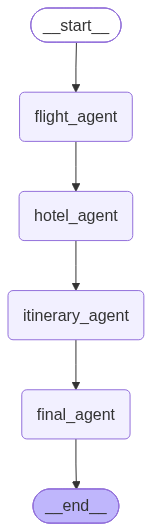

In [ ]:
# Edit database server URL to include SSL mode if not already present
def get_database_url():
    database_url = os.getenv("DATABASE_URL")

    if not database_url:
        raise ValueError(
            "DATABASE_URL is missing. Please add your Render PostgreSQL External Database URL to .env"
        )

    if "sslmode=" not in database_url:
        separator = "&" if "?" in database_url else "?"
        database_url = f"{database_url}{separator}sslmode=require"

    return database_url



# =========================
# LLM
# =========================

llm = ChatOpenAI(
        model="gpt-4o-mini",
        temperature=0.1,
        streaming=True,
        openai_api_key=OPENAI_API_KEY,
        base_url=BASE_URL
    )



# =========================
# State
# =========================

# TypedDict defines the structure of the shared state passed between agents.
class TravelState(TypedDict):

    # Stores conversation messages.
    # operator.add tells LangGraph to APPEND new messages instead of replacing the list.
    messages: Annotated[list[AnyMessage], operator.add]

    # Original user request, accessible to all agents.
    user_query: str

    # Outputs generated by the individual agents.
    flight_results: str
    hotel_results: str
    itinerary: str

    # Counter intended to track the number of LLM calls.
    llm_calls: int


# =========================
# Flight Agent
# =========================

def flight_agent(state: TravelState):

    # Read the user's request from the shared graph state.
    query = state["user_query"]

    # Call the flight-search tool to retrieve flight information.
    flight_data = search_flights(query)

    # Return only the state fields this agent wants to update.
    return {
        "flight_results": flight_data,

        # Append an AIMessage to the shared conversation history.
        "messages": [
            AIMessage(content="Flight results fetched.")
        ],

        # Increment the counter (not necessarily an actual LLM call).
        "llm_calls": state.get("llm_calls", 0) + 1
    }


# =========================
# Hotel Agent
# =========================

def hotel_agent(state: TravelState):

    # Construct a hotel-search query using the original user request.
    query = f"Best hotels for {state['user_query']}"

    # Search for hotels using the Tavily search tool.
    hotel_results = tavily_search(query)

    # Update the shared state with hotel results and a status message.
    return {
        "hotel_results": hotel_results,

        # This message is appended because messages uses operator.add.
        "messages": [
            AIMessage(content="Hotel information fetched.")
        ],

        "llm_calls": state.get("llm_calls", 0) + 1
    }


# =========================
# Itinerary Agent
# =========================

def itinerary_agent(state: TravelState):

    # Build a prompt using the user query and previously collected results.
    # This agent depends on the Flight and Hotel agents having completed.
    prompt = f"""
                Create a complete travel itinerary.

                User Query:
                {state['user_query']}

                Flight Results:
                {state['flight_results']}

                Hotel Results:
                {state['hotel_results']}

                Make the itinerary practical, budget-aware, and easy to follow.
            """

    # Invoke the LLM with a system instruction and user prompt.
    # SystemMessage defines the model's role.
    # HumanMessage contains the actual planning task.
    response = llm.invoke([
        SystemMessage(content="You are an expert travel planner."),
        HumanMessage(content=prompt)
    ])

    # Save the generated itinerary in the shared graph state.
    return {
        "itinerary": response.content,

        # Append the full LLM response to conversation history.
        "messages": [response],

        # One explicit LLM invocation occurred in this function.
        "llm_calls": state.get("llm_calls", 0) + 1
    }


# =========================
# Final Response Agent
# =========================

def final_agent(state: TravelState):

    # Combine all agent outputs into a single prompt for the final response.
    final_prompt = f"""
                        Generate the final travel response for the user.

                        User Request:
                        {state['user_query']}

                        Flights:
                        {state['flight_results']}

                        Hotels:
                        {state['hotel_results']}

                        Itinerary:
                        {state['itinerary']}

                        Format the final answer beautifully using these sections:

                        1. Trip Summary
                        2. Flight Information
                        3. Hotel Suggestions
                        4. Day-by-Day Itinerary
                        5. Estimated Budget
                        6. Final Recommendations

                        Important:
                        - Be clear and practical.
                        - Mention that live flight API may not provide ticket prices if pricing is unavailable.
                        - Keep the response useful for real travel planning.
                    """

    # Invoke the LLM to synthesize the final user-facing response.
    response = llm.invoke([
        SystemMessage(
            content="You are a professional AI travel booking assistant."
        ),
        HumanMessage(content=final_prompt)
    ])

    return {
        # The final answer is appended to messages.
        # It can later be retrieved as the last message in the state.
        "messages": [response],

        "llm_calls": state.get("llm_calls", 0) + 1
    }


# =========================
# Build Graph
# =========================

# Create a LangGraph workflow using TravelState as the shared state schema.
graph = StateGraph(TravelState)

# Register each Python function as a node in the graph.
graph.add_node("flight_agent", flight_agent)
graph.add_node("hotel_agent", hotel_agent)
graph.add_node("itinerary_agent", itinerary_agent)
graph.add_node("final_agent", final_agent)

# Define the execution order using directed edges.
graph.add_edge(START, "flight_agent")                 # Entry point
graph.add_edge("flight_agent", "hotel_agent")         # Flight -> Hotel
graph.add_edge("hotel_agent", "itinerary_agent")      # Hotel -> Itinerary
graph.add_edge("itinerary_agent", "final_agent")       # Itinerary -> Final
graph.add_edge("final_agent", END)                    # Exit point

graph.compile()

In [ ]:
# =========================
# PostgreSQL Checkpointer
# =========================

# Retrieve the PostgreSQL connection URL from project configuration.
DATABASE_URL = get_database_url()

# Establish a database connection for storing LangGraph checkpoints.
_conn = psycopg.connect(
    DATABASE_URL,

    # Commit database operations automatically.
    autocommit=True,

    # Return database rows as dictionaries.
    row_factory=dict_row
)

# Create a PostgreSQL-backed LangGraph checkpoint manager.
checkpointer = PostgresSaver(_conn)

# Create/check the database tables required by the checkpointer.
checkpointer.setup()

# Compile the graph into an executable workflow.
# The checkpointer enables persistent state associated with a thread_id.
travel_graph = graph.compile(checkpointer=checkpointer)


# =========================
# Function for FastAPI
# =========================

def run_travel_agent(user_input: str, thread_id: str | None = None):

    # Generate a unique thread ID if the user starts a new conversation.
    if not thread_id:
        thread_id = f"user_{uuid.uuid4().hex}"

    # LangGraph uses thread_id to identify the checkpoint history.
    # Reusing the same thread_id allows access to previously saved state.
    config = {
        "configurable": {
            "thread_id": thread_id
        }
    }

    # Execute the entire graph, starting from its START node.
    # The dictionary initializes the state fields for this invocation.
    result = travel_graph.invoke(
        {
            # Add the current user message to conversation history.
            "messages": [
                HumanMessage(content=user_input)
            ],

            "user_query": user_input,

            # Initialize outputs before agents populate them.
            "flight_results": "",
            "hotel_results": "",
            "itinerary": "",

            # Reset the counter for this graph invocation.
            "llm_calls": 0
        },
        config=config
    )

    # The final agent appends its response to messages.
    # Retrieve the last message as the final answer.
    final_answer = result["messages"][-1].content

    # Return structured results for the FastAPI endpoint.
    # The frontend can use these fields to render different sections.
    return {
        "thread_id": thread_id,
        "answer": final_answer,
        "flight_results": result.get("flight_results", ""),
        "hotel_results": result.get("hotel_results", ""),
        "itinerary": result.get("itinerary", ""),
        "llm_calls": result.get("llm_calls", 0),
    }


## Backend test

![Screenshot 2026-10-21 105102.png](<attachment:Screenshot 2026-10-21 105102.png>)
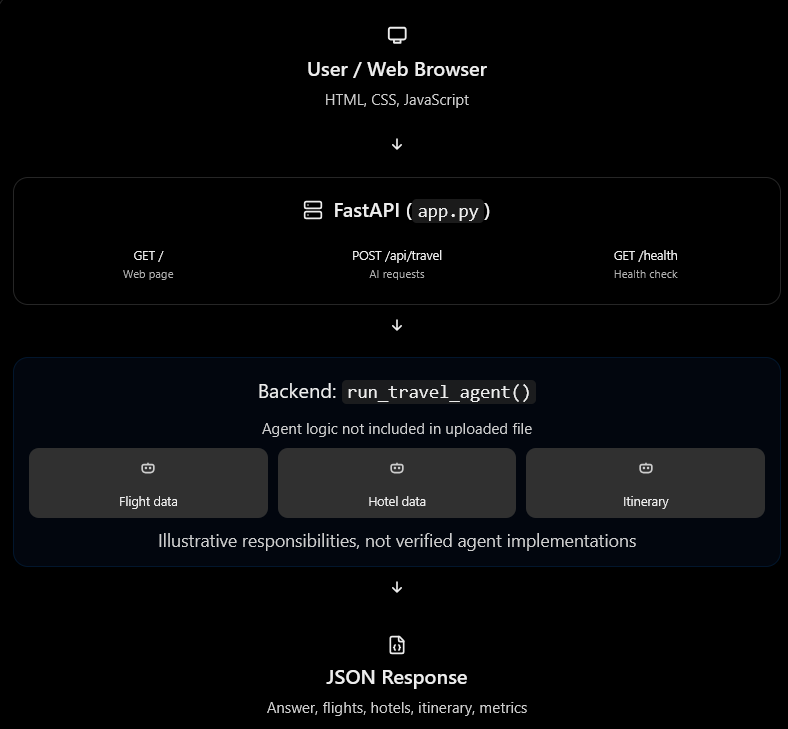

In [ ]:

from pathlib import Path  # Handle filesystem paths
import traceback          # Print detailed error tracebacks
import uvicorn            # ASGI server used to run FastAPI

from fastapi import FastAPI, Request
from fastapi.responses import HTMLResponse, JSONResponse
from fastapi.staticfiles import StaticFiles
from fastapi.templating import Jinja2Templates
from pydantic import BaseModel

# Import the function that executes the LangGraph multi-agent workflow.
from backend import run_travel_agent


# =========================
# FastAPI Configuration
# =========================

# Get the absolute directory containing this Python file.
# Used to locate the frontend's static files and HTML templates.
BASE_DIR = Path(__file__).resolve().parent

# Create the FastAPI application instance.
app = FastAPI(
    title="Travel AI Planner",
    description="LangGraph Multi-Agent Travel Planner with FastAPI Frontend",
    version="1.0.0"
)


# =========================
# Static Files
# =========================

# Serve CSS, JavaScript, images, etc. from the "static" folder.
app.mount(
    "/static",
    StaticFiles(directory=str(BASE_DIR / "static")),
    name="static"
)


# =========================
# HTML Templates
# =========================

# Configure Jinja2 to load HTML pages from the "templates" folder.
templates = Jinja2Templates(
    directory=str(BASE_DIR / "templates")
)


# =========================
# Request Model
# =========================

# Pydantic model defining the expected JSON body of POST requests.
class TravelRequest(BaseModel):

    # User's travel question or request (required).
    message: str

    # Optional conversation ID used to retrieve existing LangGraph state.
    # If omitted, the backend generates a new thread_id.
    thread_id: str | None = None


# =========================
# Home Page Endpoint
# =========================

@app.get("/", response_class=HTMLResponse)
async def home(request: Request):

    # Render templates/index.html and return it to the browser.
    return templates.TemplateResponse(
        request=request,
        name="index.html",
        context={}  # No additional template variables are provided.
    )


# =========================
# Travel Planner API Endpoint
# =========================

# POST "/api/travel" receives JSON requests from the frontend.
# FastAPI automatically validates the request using TravelRequest.
@app.post("/api/travel")
async def travel_planner(request_data: TravelRequest):
    try:

        # Extract the user's message and remove leading/trailing spaces.
        user_message = request_data.message.strip()

        # Reject empty messages before calling the AI agents.
        if not user_message:
            return JSONResponse(
                status_code=400,  # HTTP Bad Request
                content={
                    "success": False,
                    "error": "Message cannot be empty."
                }
            )

        # Execute the LangGraph multi-agent workflow in backend.py.
        # Pass the user's message and optional conversation thread ID.
        result = run_travel_agent(
            user_input=user_message,
            thread_id=request_data.thread_id
        )

        # Return the results as JSON to the frontend JavaScript.
        return JSONResponse(
            content={
                "success": True,

                # Conversation ID for maintaining the same LangGraph thread.
                "thread_id": result["thread_id"],

                # Final AI-generated response from the Final Agent.
                "answer": result["answer"],

                # Individual outputs generated by the agents.
                "flight_results": result["flight_results"],
                "hotel_results": result["hotel_results"],
                "itinerary": result["itinerary"],

                # Counter returned by the backend.
                "llm_calls": result["llm_calls"],
            }
        )

    # Catch unexpected errors during the API request.
    except Exception as e:

        # Print the error and full traceback in the server terminal.
        print("ERROR:", e)
        traceback.print_exc()

        # Return HTTP 500 if the backend fails.
        return JSONResponse(
            status_code=500,
            content={
                "success": False,
                "error": str(e)
            }
        )


# =========================
# Health Check Endpoint
# =========================

# GET "/health" checks whether the FastAPI server is responding.
# Useful for Docker, deployment platforms, and service monitoring.
@app.get("/health")
async def health_check():
    return {
        "status": "ok",
        "message": "AI Travel Planner API is running"
    }


# =========================
# Favicon Endpoint
# =========================

# Handle browser requests for /favicon.ico.
# Currently returns empty JSON instead of a favicon image.
@app.get("/favicon.ico")
async def favicon():
    return JSONResponse(content={})


# =========================
# Run FastAPI Server
# =========================

# Execute this block only when app.py is run directly.
if __name__ == "__main__":

    # Start the FastAPI application using Uvicorn.
    uvicorn.run(
        "app:app",        # Import the FastAPI instance "app" from app.py
        host="127.0.0.1", # Accept connections from the local machine
        port=8000,        # Run the server on port 8000
        reload=True       # Restart server when Python code changes
    )


## Docker image test

![Screenshot 2026-10-21 150613.png](<attachment:Screenshot 2026-10-21 150613.png>)
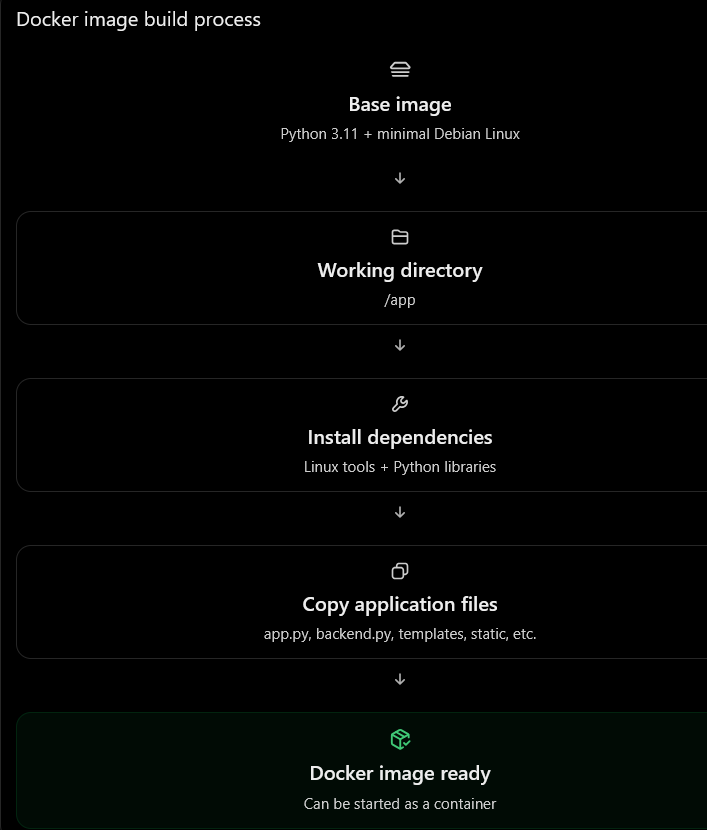

In [ ]:

# Use Python 3.11 on a lightweight Debian Linux image.
FROM python:3.11-slim

# Set /app as the working directory inside the container.
# All following commands execute relative to this directory.
WORKDIR /app

# Prevent Python from generating .pyc bytecode files.
ENV PYTHONDONTWRITEBYTECODE=1

# Disable Python output buffering so logs appear immediately.
ENV PYTHONUNBUFFERED=1

# Install Linux packages required by some Python dependencies.
RUN apt-get update && apt-get install -y \
    build-essential \
    git \
    curl \
    && rm -rf /var/lib/apt/lists/*

# Copy the local requirements.txt into /app in the image.
COPY requirements.txt .

# Upgrade pip inside the image.
RUN pip install --no-cache-dir --upgrade pip

# Install all Python packages listed in requirements.txt.
RUN pip install --no-cache-dir -r requirements.txt

# Copy the remaining project files into /app.
COPY . .

# Document that the application listens on port 8000.
# EXPOSE does not actually publish the port to your computer.
EXPOSE 8000

# Default command executed when the container starts.
# 0.0.0.0 allows connections through the container network.
CMD ["uvicorn", "app:app", "--host", "0.0.0.0", "--port", "8000"]
